# 06 · Polls against results

Part 2 of the study plan (`docs/study_plan.md`): how much coordination the polls show, toward whom, and how they
compare with the result. Built block by block: **structure metrics**, then the split of the change in concentration,
poll error by role, the cliff, the last weeks, momentum, and a table of stylized facts.

Each poll is read through its ballot scenario, with every candidate it tests, including those who will not be on the
ballot: that is what voters saw. Shares are rescaled to 100 unless marked *raw*.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from polls import average, figures, ideology, metrics, timeline

pd.set_option("display.width", 200)
TABLES, FIGURES = ROOT / "results" / "tables", ROOT / "results" / "figures"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3, "font.size": 9})

calendar = timeline.load(ROOT / "config" / "elections.yaml")
rows = timeline.add_time(pd.read_csv(ROOT / "data" / "final" / "polls.csv", low_memory=False), calendar)
results = pd.read_csv(ROOT / "data" / "interim" / "results.csv")
ELECTIONS = sorted(rows["election"].unique())
ballot = rows[rows["ballot_scenario"] & (rows["share_status"] != "not_tested")]
# one colour per election, from the same left-right palette's ends inward (no ideological meaning here)
E_COLOURS = dict(zip(ELECTIONS, ["#9e0142", "#f46d43", "#e09000", "#2a9d8f", "#5e4fa2"]))

## 1 · Structure metrics

For each poll's ballot scenario and each result: HHI (rescaled and raw) and ENP = 1 / HHI; the top-two share; the
**cliff** as in the ABM: the largest drop between consecutive sorted shares (points), its **location** (how many
candidates sit above it) and its **ratio** (near 1: sharp; near 0.5: diffuse); the gap between the 2nd and the 3rd
(`gap_23`), which decides qualification; the 1st–2nd and 3rd–4th gaps; the number of candidates within 5 points of
the 2nd (the 2nd included).

In [2]:
per_poll = []
for (e, pid), g in ballot.groupby(["election", "poll_id"]):
    st = metrics.structure(metrics.shares_of(g))
    per_poll.append(dict(election=e, poll_id=pid, days_before=g["days_before"].iloc[0], phase=g["phase"].iloc[0],
                         n_extra=int(g["slot"].isna().sum()), **st))
per_poll = pd.DataFrame(per_poll)
per_poll.round(4).to_csv(TABLES / "structure_by_poll.csv", index=False)

res_rows = results.assign(share_status="value", share_upper_bound=np.nan)
per_result = pd.DataFrame([dict(election=e, **metrics.structure(metrics.shares_of(g)))
                           for e, g in res_rows.groupby("election")]).set_index("election")
per_result.round(4).to_csv(TABLES / "structure_results.csv")
cols = ["n_candidates", "hhi", "enp", "top2_share", "cliff", "cliff_location", "cliff_ratio", "gap_12", "gap_23",
        "gap_34", "n_in_contention", "first", "second", "third"]
print("Results:")
per_result[cols].round(3)

Results:


,n_candidates,hhi,enp,top2_share,cliff,cliff_location,cliff_ratio,gap_12,gap_23,gap_34,n_in_contention,first,second,third
election,,,,,,,,,,,,,,
2002,16,0.115,8.659,36.74,9.34,3,0.928,3.02,0.68,9.34,2,Jacques Chirac,Jean-Marie Le Pen,Lionel Jospin
2007,12,0.213,4.700,57.05,8.13,3,0.782,5.31,7.30,8.13,1,Nicolas Sarkozy,Ségolène Royal,François Bayrou
2012,10,0.210,4.772,55.81,9.28,2,0.795,1.45,9.28,6.80,1,François Hollande,Nicolas Sarkozy,Marine Le Pen
2017,11,0.188,5.318,45.31,13.22,4,0.918,2.71,1.29,0.43,3,Emmanuel Macron,Marine Le Pen,François Fillon
2022,12,0.191,5.231,51.00,14.88,3,0.923,4.70,1.20,14.88,2,Emmanuel Macron,Marine Le Pen,Jean-Luc Mélenchon


### The last polls against the result

Mean over the polls of the last two weeks, against the result. *Raw HHI* uses shares as published (they can sum below
100 when small candidates are missing), so it is lower than the rescaled HHI in 2007 and 2012.

In [3]:
last = per_poll[per_poll["phase"] == timeline.PHASES[2]]
num = ["hhi", "hhi_raw", "enp", "top2_share", "cliff", "cliff_location", "cliff_ratio", "gap_12", "gap_23",
       "gap_34", "n_in_contention", "total"]
cmp = pd.concat({"last polls": last.groupby("election")[num].mean(),
                 "result": per_result[num]}, axis=1).swaplevel(axis=1).sort_index(axis=1, level=0)
for m in num:
    cmp[(m, "difference")] = cmp[(m, "result")] - cmp[(m, "last polls")]
cmp = cmp.reindex(columns=pd.MultiIndex.from_product([num, ["last polls", "result", "difference"]]))
cmp.round(3).to_csv(TABLES / "structure_last_polls_vs_result.csv")
cmp[["hhi", "enp", "top2_share", "cliff", "cliff_location", "gap_23"]].round(3)

hhi                          enp                   top2_share                        cliff                   cliff_location                       gap_23                  
         last polls result difference last polls result difference last polls result difference last polls result difference     last polls result difference last polls result difference
election                                                                                                                                                                                  
2002          0.115  0.115      0.001      8.732  8.659     -0.073     38.000  36.74     -1.260      6.125   9.34      3.215          2.500      3      0.500      5.250   0.68     -4.570
2007          0.196  0.213      0.017      5.099  4.700     -0.399     52.444  57.05      4.606      9.944   8.13     -1.814          3.611      3     -0.611      5.528   7.30      1.772
2012          0.207  0.210      0.003      4.834  4.772     -0.062     55.042  55.81      0.768     11.042   9.28     -1.762          2.500      2     -0.500     10.833   9.28     -1.553
2017          0.187  0.188      0.001      5.340  5.318     -0.022     46.182  45.31     -0.872     10.523  13.22      2.697          4.000      4      0.000      2.955   1.29     -1.665
2022          0.171  0.191      0.021      5.867  5.231     -0.636     48.986  51.00      2.014      7.576  14.88      7.304          2.138      3      0.862      5.990   1.20     -4.790

### Over the campaign

Poll average of each metric over the last 250 days (same kernel as in notebook 05; where polls are sparse the window
widens to the 4th-nearest poll, drawn pale); dots at 0 are the results.

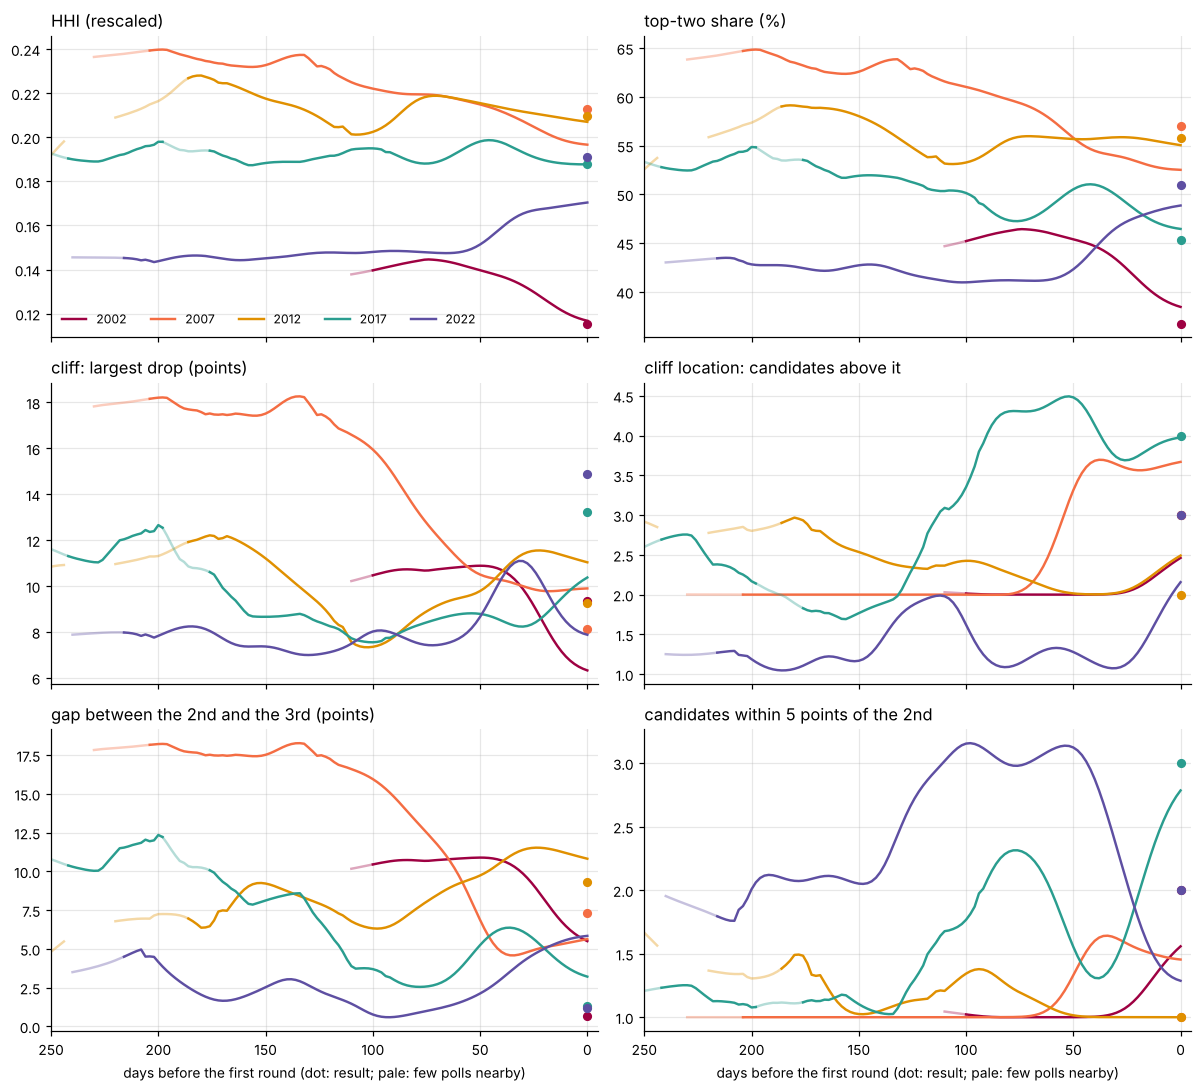

In [4]:
GRID = np.arange(0, 366, 2)
show = {"hhi": "HHI (rescaled)", "top2_share": "top-two share (%)",
        "cliff": "cliff: largest drop (points)", "cliff_location": "cliff location: candidates above it",
        "gap_23": "gap between the 2nd and the 3rd (points)", "n_in_contention": "candidates within 5 points of the 2nd"}
fig, axes = plt.subplots(3, 2, figsize=(11, 10), sharex=True)
evol = []
for ax, (m, label) in zip(axes.flat, show.items()):
    for e in ELECTIONS:
        d = per_poll[per_poll["election"] == e]
        x, y = d["days_before"].to_numpy(), d[m].to_numpy(dtype=float)
        evol.append(average.smooth(x, y, GRID).assign(metric=m, election=e).reset_index())   # strict, for the table
        s = average.smooth(x, y, GRID, adaptive_k=4)                                          # widened, for drawing
        figures.line(ax, s.index, s["mean"], s["sparse"], color=E_COLOURS[e], lw=1.6, label=str(e))
        ax.plot(0, per_result.loc[e, m], "o", color=E_COLOURS[e], ms=5)
    ax.set_title(label, loc="left")
axes[0, 0].legend(frameon=False, ncol=5, fontsize=8)
for ax in axes[-1]:
    ax.set_xlim(250, -5); ax.set_xlabel("days before the first round (dot: result; pale: few polls nearby)")
fig.tight_layout()
fig.savefig(FIGURES / "structure_over_campaign.png")
pd.concat(evol).query("days_before % 14 == 0").round(4).to_csv(TABLES / "structure_poll_average.csv", index=False)

## 2 · Where the change in concentration comes from

HHI is computed twice for every ballot poll and for the result:

- **all**: every candidate the poll tests, extra candidates included (what voters saw);
- **core**: only the final candidacies with at least 2% of the vote (the slots every ballot scenario must fill), rescaled
  among themselves. The same candidates in every poll and in the result, so its changes are **voters moving**.

The difference, all − core, is the **composition** effect: extra candidates who will withdraw, small candidates who
are tested or not. Its changes are **the offer changing** (withdrawals: elite coordination).

Three anchors: the **opening** (ballot polls of the first 30 days within the last 250 days), the **last polls** (last two
weeks) and the **result**. The change from opening to last polls is the *campaign*; from last polls to result, the
*last mile*.

In [5]:
core_slots = results[results["share"] >= 2.0].groupby("election")["candidate"].apply(set)
b = ballot.copy()
b["value"] = np.where(b["share_status"] == "value", b["share"], b["share_upper_bound"] * 0.5)
core = (b[[s in core_slots[e] for e, s in zip(b["election"], b["slot"])]]
        .groupby(["election", "poll_id", "slot"])["value"].sum().groupby(["election", "poll_id"])
        .apply(lambda v: metrics.hhi(v.to_numpy())).rename("hhi_core"))
per_poll = per_poll.merge(core.reset_index(), on=["election", "poll_id"])
per_poll["composition"] = per_poll["hhi"] - per_poll["hhi_core"]

res_core = pd.Series({e: metrics.hhi(results[(results["election"] == e) & (results["share"] >= 2.0)]["share"].to_numpy())
                      for e in ELECTIONS})

rows_ = []
for e in ELECTIONS:
    d = per_poll[(per_poll["election"] == e) & (per_poll["days_before"] <= 250)]
    d0 = d["days_before"].max()
    opening = d[d["days_before"] >= d0 - 30]
    lastp = d[d["phase"] == timeline.PHASES[2]]
    anchors = {"opening": opening, "last polls": lastp}
    r = dict(election=e, opening_from=int(d0), opening_to=int(opening["days_before"].min()),
             opening_polls=len(opening), last_polls=len(lastp))
    for k, a in anchors.items():
        r[f"{k}: all"], r[f"{k}: core"] = a["hhi"].mean(), a["hhi_core"].mean()
    r["result: all"], r["result: core"] = per_result.loc[e, "hhi"], res_core[e]
    rows_.append(r)
anchors = pd.DataFrame(rows_).set_index("election")
for seg, (a, b_) in {"campaign": ("opening", "last polls"), "last mile": ("last polls", "result")}.items():
    anchors[f"{seg}: total"] = anchors[f"{b_}: all"] - anchors[f"{a}: all"]
    anchors[f"{seg}: voters (core)"] = anchors[f"{b_}: core"] - anchors[f"{a}: core"]
    anchors[f"{seg}: offer (composition)"] = anchors[f"{seg}: total"] - anchors[f"{seg}: voters (core)"]
anchors.round(4).to_csv(TABLES / "concentration_decomposition.csv")
print("Opening window (days before) and polls:")
print(anchors[["opening_from", "opening_to", "opening_polls", "last_polls"]].to_string())
print()
print("Change in HHI, split (rescaled HHI; positive = more concentrated):")
anchors[[c for c in anchors.columns if c.startswith(("campaign", "last mile"))]].round(3)

Opening window (days before) and polls:
          opening_from  opening_to  opening_polls  last_polls
election                                                     
2002                71          43             16          12
2007               199         186              4          18
2012               232         230              2          12
2017               230         214              5          22
2022               220         191              6          29

Change in HHI, split (rescaled HHI; positive = more concentrated):


,campaign: total,campaign: voters (core),campaign: offer (composition),last mile: total,last mile: voters (core),last mile: offer (composition)
election,,,,,,
2002,-0.027,-0.032,0.005,0.001,0.002,-0.001
2007,-0.043,-0.041,-0.002,0.017,0.011,0.005
2012,0.023,-0.020,0.042,0.003,0.007,-0.004
2017,-0.003,-0.009,0.006,0.001,0.001,0.000
2022,0.026,0.006,0.020,0.021,0.020,0.000


In [6]:
print("HHI at each anchor:")
anchors[["opening: all", "opening: core", "last polls: all", "last polls: core", "result: all", "result: core"]].round(3)

HHI at each anchor:


,opening: all,opening: core,last polls: all,last polls: core,result: all,result: core
election,,,,,,
2002,0.142,0.153,0.115,0.121,0.115,0.124
2007,0.239,0.278,0.196,0.237,0.213,0.248
2012,0.184,0.239,0.207,0.219,0.210,0.226
2017,0.190,0.212,0.187,0.203,0.188,0.204
2022,0.145,0.177,0.171,0.183,0.191,0.203


### Over the campaign

HHI of all candidates against the core, per election (poll averages; pale where polls are few). The gap between the
two lines is the composition effect: it closes when extra candidates withdraw.

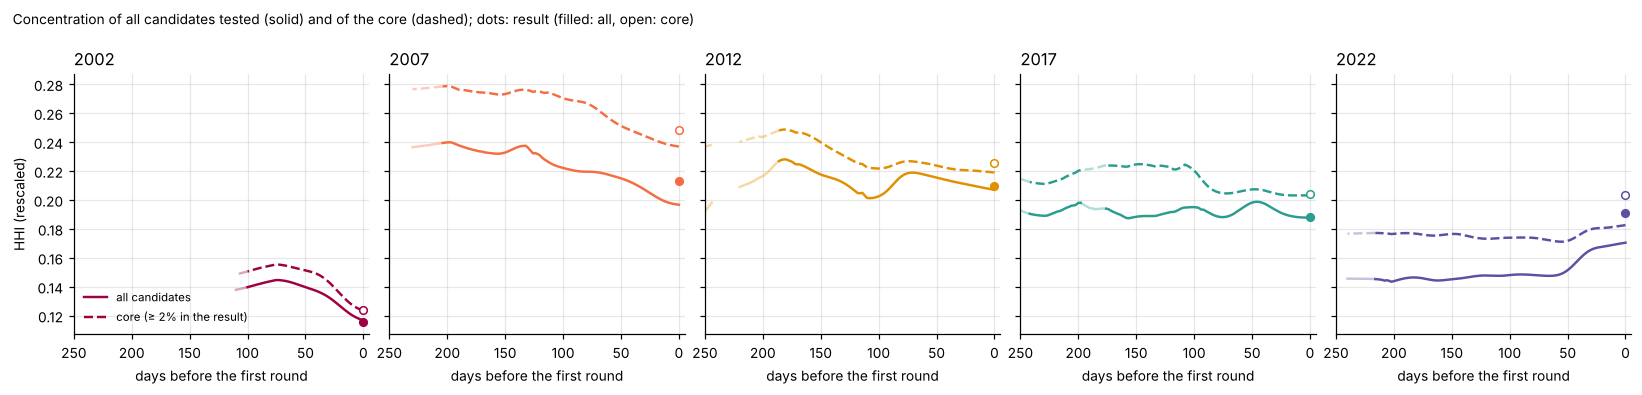

In [7]:
fig, axes = plt.subplots(1, len(ELECTIONS), figsize=(15, 3.6), sharey=True)
for ax, e in zip(axes, ELECTIONS):
    d = per_poll[per_poll["election"] == e]
    for m, ls, label in (("hhi", "-", "all candidates"), ("hhi_core", "--", "core (≥ 2% in the result)")):
        s = average.smooth(d["days_before"].to_numpy(), d[m].to_numpy(dtype=float), GRID, adaptive_k=4)
        figures.line(ax, s.index, s["mean"], s["sparse"], color=E_COLOURS[e], lw=1.6, ls=ls, label=label)
    ax.plot(0, per_result.loc[e, "hhi"], "o", color=E_COLOURS[e], ms=5)
    ax.plot(0, res_core[e], "o", mfc="white", color=E_COLOURS[e], ms=5)
    ax.set_title(str(e), loc="left"); ax.set_xlim(250, -5)
    ax.set_xlabel("days before the first round")
axes[0].set_ylabel("HHI (rescaled)")
axes[0].legend(frameon=False, fontsize=7.5, loc="lower left")
fig.suptitle("Concentration of all candidates tested (solid) and of the core (dashed); dots: result (filled: all, open: core)",
             x=0.01, ha="left", fontsize=9)
fig.tight_layout()
fig.savefig(FIGURES / "concentration_all_vs_core.png")

## 3 · Poll error by role

**Error** = result − mean of the last two weeks of polls, in points (positive: the candidate did better than polled),
per final candidacy (its slot). Relative error = error / polled share. **Roles** come from that mean (the poll average,
not single polls): 1st, 2nd, 3rd, 4th, then the rest; *contenders* are the candidates within 5 points of the 2nd.

The error mixes poll bias and real late movement (strategic or not); the two cannot be told apart here. Candidates
absent from the last polls (some small ones in 2007 and 2012) have no error.

In [8]:
lastb = b[(b["phase"] == timeline.PHASES[2]) & b["slot"].notna()]
per_slot = lastb.groupby(["election", "poll_id", "slot"])["value"].sum().reset_index()
polled = per_slot.groupby(["election", "slot"]).agg(polled=("value", "mean"), polls=("poll_id", "nunique")).reset_index()
n_last = per_slot.groupby("election")["poll_id"].nunique()
polled["coverage"] = polled["polls"] / polled["election"].map(n_last)
err = results.rename(columns={"candidate": "slot", "share": "result"})[["election", "slot", "result"]].merge(polled, how="left")
err["error"] = err["result"] - err["polled"]
err["relative_error"] = err["error"] / err["polled"]
err["rank"] = err.groupby("election")["polled"].rank(ascending=False, method="min")
second = err[err["rank"] == 2].set_index("election")["polled"]
err["role"] = np.select([err["rank"] == 1, err["rank"] == 2, err["rank"] == 3, err["rank"] == 4],
                        ["1st", "2nd", "3rd", "4th"], "5th and below")
err.loc[err["polled"].isna(), "role"] = "not in last polls"
err["contender"] = (err["rank"] > 2) & (err["polled"] >= err["election"].map(second) - 5)
lr = ideology.order(ROOT, {int(p.name[:4]): p for p in (ROOT / "data" / "raw" / "wikipedia").glob("*.json")},
                    pd.read_csv(ROOT / "data" / "interim" / "polls_wikipedia.csv", low_memory=False))
err = err.merge(lr.rename(columns={"candidate": "slot"}), how="left")
err.round(3).to_csv(TABLES / "error_by_candidate.csv", index=False)
print("Error by candidate (sorted by polled share):")
err.sort_values(["election", "polled"], ascending=[True, False])[
    ["election", "slot", "role", "contender", "polled", "result", "error", "relative_error", "coverage"]].round(2)

Error by candidate (sorted by polled share):


,election,slot,role,contender,polled,result,error,relative_error,coverage
12,2002,Jacques Chirac,1st,False,20.04,19.88,-0.16,-0.01,1.0
4,2002,Lionel Jospin,2nd,False,17.96,16.18,-1.78,-0.10,1.0
14,2002,Jean-Marie Le Pen,3rd,False,12.71,16.86,4.15,0.33,1.0
0,2002,Arlette Laguiller,4th,False,7.62,5.72,-1.91,-0.25,1.0
7,2002,Jean-Pierre Chevènement,5th and below,False,6.58,5.33,-1.25,-0.19,1.0
...,...,...,...,...,...,...,...,...,...
57,2022,Jean Lassalle,5th and below,False,2.54,3.13,0.59,0.23,1.0
58,2022,Nicolas Dupont-Aignan,5th and below,False,2.22,2.06,-0.16,-0.07,1.0
54,2022,Anne Hidalgo,5th and below,False,1.96,1.75,-0.21,-0.11,1.0
49,2022,Philippe Poutou,5th and below,False,1.03,0.77,-0.26,-0.25,1.0


In [9]:
pooled = err.dropna(subset=["error"]).groupby("role").agg(
    candidates=("slot", "size"), mean_error=("error", "mean"), mean_relative_error=("relative_error", "mean"),
    did_better=("error", lambda x: int((x > 0).sum())), did_worse=("error", lambda x: int((x < 0).sum())))
pooled = pooled.reindex(["1st", "2nd", "3rd", "4th", "5th and below"])
contenders = err[err["contender"]].agg(candidates=("slot", "size"), mean_error=("error", "mean"))
pooled.round(2).to_csv(TABLES / "error_by_role.csv")
print("Pooled over the five elections:")
print(pooled.round(2).to_string())
print()
print("Contenders (3rd and below, within 5 points of the 2nd):")
err[err["contender"]][["election", "slot", "role", "polled", "result", "error"]].round(2)

Pooled over the five elections:
               candidates  mean_error  mean_relative_error  did_better  did_worse
role                                                                             
1st                     5        0.93                 0.03           4          1
2nd                     5       -0.01                -0.01           3          2
3rd                     5        2.60                 0.17           5          0
4th                     5       -2.11                -0.19           1          4
5th and below          41       -0.19                 0.01          19         22

Contenders (3rd and below, within 5 points of the 2nd):


,election,slot,role,polled,result,error
40,2017,Jean-Luc Mélenchon,4th,18.89,19.58,0.69
44,2017,François Fillon,3rd,19.23,20.01,0.78


### Who gains, who loses, along the left-right axis

Candidates in the order of Wikipedia's poll-table columns (left to right), coloured accordingly. Bars: the error;
labels: the polled share. Outlined: the 2nd and the 3rd in the last polls.

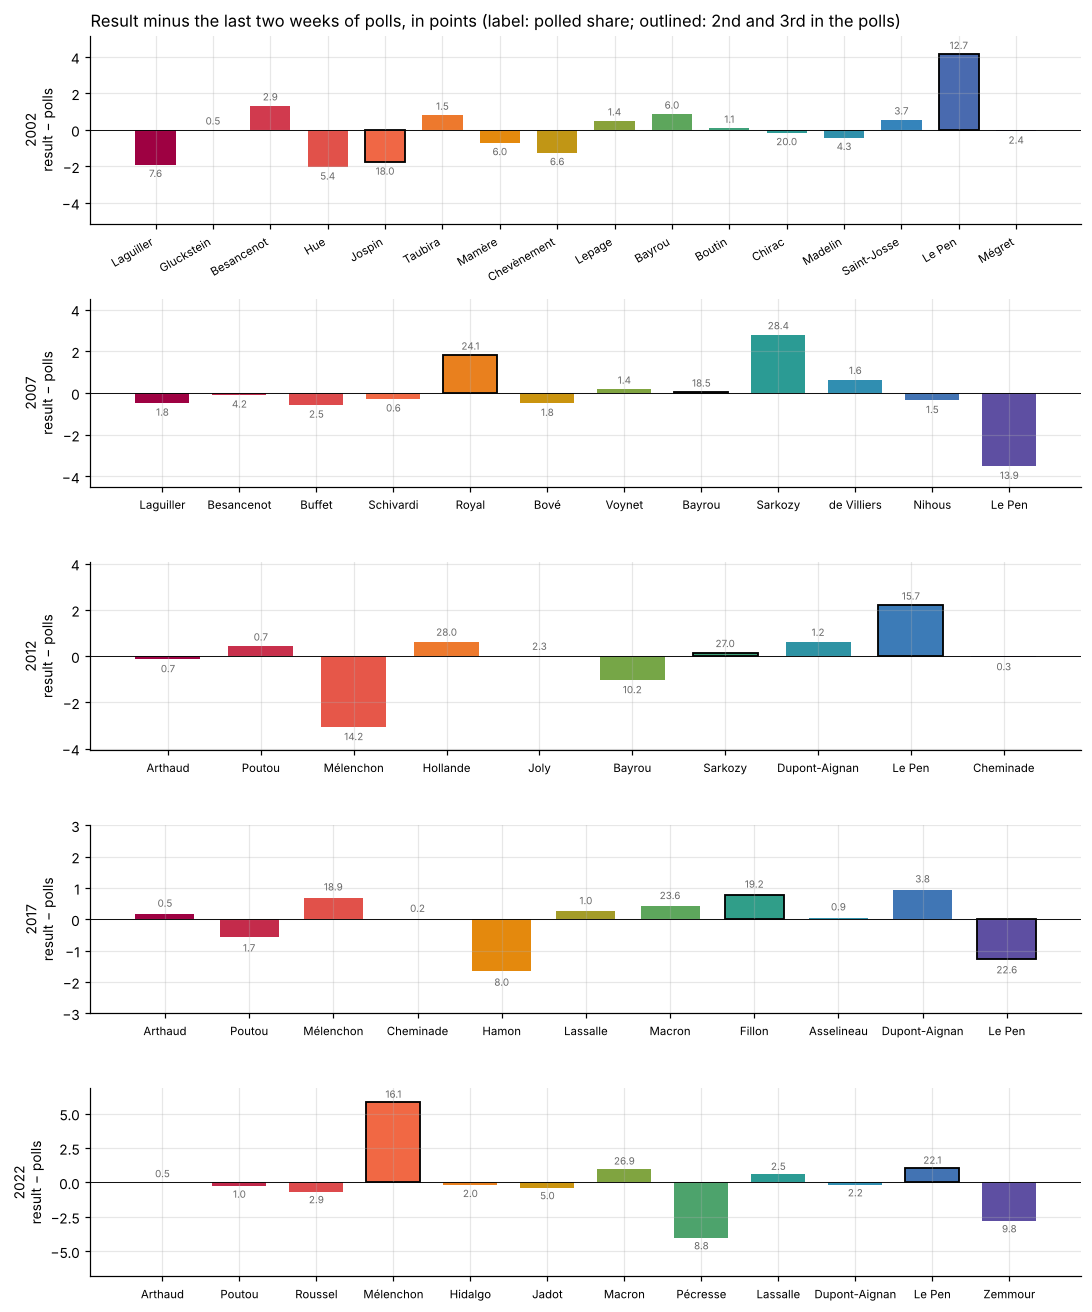

In [10]:
fig, axes = plt.subplots(len(ELECTIONS), 1, figsize=(10, 12))
for ax, e in zip(axes, ELECTIONS):
    d = err[(err["election"] == e) & err["error"].notna()].sort_values("position")
    col = ideology.colours(d["slot"].tolist())
    x = np.arange(len(d))
    bars = ax.bar(x, d["error"], color=[col[s] for s in d["slot"]], width=0.7)
    for xi, r, bar in zip(x, d.itertuples(), bars):
        if r.role in ("2nd", "3rd"):
            bar.set_edgecolor("black"); bar.set_linewidth(1.2)
        ax.text(xi, r.error + (0.15 if r.error >= 0 else -0.15), f"{r.polled:.1f}", ha="center",
                va="bottom" if r.error >= 0 else "top", fontsize=6.5, color="dimgrey")
    ax.axhline(0, color="black", lw=0.6)
    ax.set_xticks(x, [s.split(" ", 1)[1] for s in d["slot"]], fontsize=7.5,
                  rotation=30 if len(d) > 12 else 0, ha="right" if len(d) > 12 else "center")
    ax.set_ylabel(f"{e}\nresult − polls")
    lim = max(3, d["error"].abs().max() + 1); ax.set_ylim(-lim, lim)
axes[0].set_title("Result minus the last two weeks of polls, in points (label: polled share; outlined: 2nd and 3rd in the polls)",
                  loc="left")
fig.tight_layout()
fig.savefig(FIGURES / "error_left_right.png")

### How accurate was each poll?

Each poll of the last two weeks against the result: its **error on a typical candidate**, the root mean square of
poll − result over the final candidacies it tests (shares as published, in points), and its largest miss. The poll
average is shown alongside: averaging removes much of the noise of single polls, but not what all polls miss together.

Polls of one election are not independent: they share the same late movement and the same common misses. So the
spread within an election mostly shows how pollsters differ; the difference between elections is five cases, not a
trend.

In [11]:
acc = per_slot.merge(results.rename(columns={"candidate": "slot", "share": "result"})[["election", "slot", "result"]])
acc["error"] = acc["value"] - acc["result"]
info = lastb.groupby("poll_id").agg(institute=("institute_family", "first"), date=("date", "first"),
                                     days_before=("days_before", "first"))
worst = acc.loc[acc.groupby("poll_id")["error"].apply(lambda x: x.abs().idxmax())].set_index("poll_id")
by_poll = (acc.groupby(["election", "poll_id"])
           .agg(candidates=("slot", "size"), rmse=("error", lambda x: np.sqrt((x ** 2).mean())),
                mae=("error", lambda x: x.abs().mean()))
           .reset_index().join(info, on="poll_id"))
by_poll["largest_miss"] = by_poll["poll_id"].map(worst["slot"])
by_poll["largest_miss_error"] = by_poll["poll_id"].map(worst["error"])
by_poll.round(3).to_csv(TABLES / "error_by_poll.csv", index=False)

avg_err = err.dropna(subset=["error"]).groupby("election")["error"].apply(lambda x: np.sqrt((x ** 2).mean()))
print("Error on a typical candidate (RMSE, points), polls of the last two weeks:")
by_poll.groupby("election")["rmse"].describe()[["count", "mean", "min", "50%", "max"]].assign(
    poll_average=avg_err).round(2)

Error on a typical candidate (RMSE, points), polls of the last two weeks:


,count,mean,min,50%,max,poll_average
election,,,,,,
2002,12.0,1.60,1.12,1.56,2.20,1.46
2007,18.0,1.62,0.96,1.61,2.31,1.44
2012,12.0,1.46,0.93,1.44,2.30,1.28
2017,22.0,0.94,0.33,0.94,1.60,0.80
2022,29.0,2.38,1.61,2.43,3.18,2.25


## 4 · The cliff for qualification

**The gap between the 2nd and the 3rd** decides the runoff. At three horizons (8, 4 and 1 week before the vote) the
poll average (strict kernel) gives each final candidacy a share, hence a 2nd, a 3rd and a gap, to compare with the
result.

**How predictable was the runoff pair?** Polls at a given horizon miss the result by a typical error. That error is the
root mean square of result − poll average over the candidates polling 5% or more at that horizon, in the **other four
elections** (leave-one-election-out, so an election's own outcome is not used to judge it). Each candidate's result
is then drawn as poll average + Normal(0, that error), independently, 20,000 times: the share of draws in which the
real runoff pair comes out on top is the probability the polls gave it. Independence and a common error for every
candidate are simplifications: a rough gauge, not a forecast model.

In [12]:
HORIZONS = {"8 weeks": 56, "4 weeks": 28, "1 week": 7}
slot_vals = b[b["slot"].notna()].groupby(["election", "poll_id", "slot"]).agg(
    value=("value", "sum"), days_before=("days_before", "first")).reset_index()
at = pd.concat([average.by_candidate(g, "value", np.array(list(HORIZONS.values()))).assign(election=e)
                for e, g in slot_vals.groupby("election")], ignore_index=True).dropna(subset=["mean"])
at = at.merge(results.rename(columns={"candidate": "slot", "share": "result"})[["election", "slot", "result"]])
at["error"] = at["result"] - at["mean"]

def rmse_without(e, d):
    x = at[(at["election"] != e) & (at["days_before"] == d) & (at["mean"] >= 5)]["error"]
    return float(np.sqrt((x ** 2).mean()))

pair = results.sort_values("share", ascending=False).groupby("election").head(2).groupby("election")["candidate"].apply(frozenset)
rng = np.random.default_rng(2026)
rows_ = []
for e in ELECTIONS:
    for h, d in HORIZONS.items():
        g = at[(at["election"] == e) & (at["days_before"] == d)].sort_values("mean", ascending=False)
        if len(g) < 3:
            continue
        sd = rmse_without(e, d)
        draws = g["mean"].to_numpy() + rng.normal(0, sd, size=(20000, len(g)))
        top2 = np.argsort(-draws, axis=1)[:, :2]
        names = g["slot"].to_numpy()
        hit = np.mean([frozenset(names[t]) == pair[e] for t in top2])
        qualify = {}
        for i, n in enumerate(names[:4]):
            qualify[f"{i + 1}. candidate"] = n.split(" ", 1)[1]
            qualify[f"{i + 1}. P(qualify)"] = np.mean((top2 == i).any(axis=1))
        rows_.append({"election": e, "horizon": h, "typical_error": sd,
                      "2nd": names[1], "3rd": names[2], "gap_23": g["mean"].iloc[1] - g["mean"].iloc[2],
                      "p_real_pair": hit, **qualify})
pred = pd.DataFrame(rows_)
pred.round(3).to_csv(TABLES / "cliff_predictability.csv", index=False)
print("Typical error of the poll average (points, candidates at 5% or more, other elections):")
print(pd.Series({h: rmse_without(-1, d) for h, d in HORIZONS.items()}).round(2).to_string())
print()
pred[["election", "horizon", "2nd", "3rd", "gap_23", "typical_error", "p_real_pair"]].round(2)

Typical error of the poll average (points, candidates at 5% or more, other elections):
8 weeks    4.82
4 weeks    3.61
1 week     2.42



,election,horizon,2nd,3rd,gap_23,typical_error,p_real_pair
0,2002,8 weeks,Lionel Jospin,Jean-Pierre Chevènement,11.97,5.00,0.03
1,2002,4 weeks,Lionel Jospin,Jean-Marie Le Pen,9.84,3.63,0.02
2,2002,1 week,Lionel Jospin,Jean-Marie Le Pen,6.11,2.48,0.04
3,2007,8 weeks,Ségolène Royal,François Bayrou,9.00,5.19,0.85
4,2007,4 weeks,Ségolène Royal,François Bayrou,4.79,3.82,0.78
5,2007,1 week,Ségolène Royal,François Bayrou,5.43,2.44,0.94
6,2012,8 weeks,Nicolas Sarkozy,Marine Le Pen,9.46,5.25,0.85
7,2012,4 weeks,François Hollande,Marine Le Pen,12.37,3.91,0.97
8,2012,1 week,Nicolas Sarkozy,Marine Le Pen,11.96,2.53,1.00
9,2017,8 weeks,Emmanuel Macron,François Fillon,4.10,4.67,0.61


In [13]:
print("Probability of qualifying, the four leading candidates at each horizon:")
pred.set_index(["election", "horizon"]).filter(regex=r"^\d\. ").round(2)

Probability of qualifying, the four leading candidates at each horizon:


1. candidate  1. P(qualify) 2. candidate  2. P(qualify) 3. candidate  3. P(qualify) 4. candidate  4. P(qualify)
election horizon                                                                                                                
2002     8 weeks       Chirac           0.95       Jospin           0.91  Chevènement           0.05       Le Pen           0.05
         4 weeks       Chirac           0.98       Jospin           0.95       Le Pen           0.03    Laguiller           0.02
         1 week        Chirac           0.99       Jospin           0.96       Le Pen           0.05    Laguiller           0.00
2007     8 weeks      Sarkozy           0.98        Royal           0.87       Bayrou           0.12       Le Pen           0.03
         4 weeks      Sarkozy           0.97        Royal           0.82       Bayrou           0.21       Le Pen           0.01
         1 week       Sarkozy           1.00        Royal           0.94       Bayrou           0.06       Le Pen           0.00
2012     8 weeks     Hollande           0.96      Sarkozy           0.88       Le Pen           0.12       Bayrou           0.03
         4 weeks      Sarkozy           0.99     Hollande           0.99       Le Pen           0.02    Mélenchon           0.00
         1 week      Hollande           1.00      Sarkozy           1.00       Le Pen           0.00    Mélenchon           0.00
2017     8 weeks       Le Pen           0.88       Macron           0.72       Fillon           0.31        Hamon           0.06
         4 weeks       Macron           0.91       Le Pen           0.89       Fillon           0.16    Mélenchon           0.04
         1 week        Macron           0.89       Le Pen           0.83       Fillon           0.17    Mélenchon           0.11
2022     8 weeks       Macron           0.98       Le Pen           0.51     Pécresse           0.25      Zemmour           0.21
         4 weeks       Macron           1.00       Le Pen           0.84    Mélenchon           0.08      Zemmour           0.05
         1 week        Macron           1.00       Le Pen           0.98    Mélenchon           0.02      Zemmour           0.00

In [14]:
print("Gap between the 2nd and the 3rd: poll average at each horizon, and the result")
res23 = per_result[["second", "third", "gap_23"]].rename(columns=lambda c: f"result: {c}")
gaps = pred.pivot(index="election", columns="horizon", values="gap_23")[list(HORIZONS)].join(res23)
gaps.round(2).to_csv(TABLES / "cliff_gap_23_by_horizon.csv")
gaps.round(2)

Gap between the 2nd and the 3rd: poll average at each horizon, and the result


,8 weeks,4 weeks,1 week,result: second,result: third,result: gap_23
election,,,,,,
2002,11.97,9.84,6.11,Jean-Marie Le Pen,Lionel Jospin,0.68
2007,9.00,4.79,5.43,Ségolène Royal,François Bayrou,7.30
2012,9.46,12.37,11.96,Nicolas Sarkozy,Marine Le Pen,9.28
2017,4.10,6.46,3.98,Marine Le Pen,François Fillon,1.29
2022,2.21,5.22,5.70,Marine Le Pen,Jean-Luc Mélenchon,1.20


## 5 · Momentum

**During the campaign.** On the strict poll average, every 7 days over the last 250, for candidates at 3% or more:
the change over the previous 3 weeks against the change over the next 3 weeks. A positive slope is momentum (a rise
tends to continue), a negative one mean reversion. Three-week steps keep the two changes on different polls (the
kernel's bandwidth is 10 days).

**Into the vote.** The change over the 4 weeks before the last week (35 → 7 days before) against the last mile (result
− poll average 7 days before), for candidates at 3% or more.

Slopes by least squares; 95% intervals by resampling whole candidate series (2,000 draws), since the points of one
candidate's series are not independent.

In [15]:
STEP, LAG = 7, 21
grid = np.arange(STEP, 252, STEP)
series = pd.concat([average.by_candidate(g, "value", grid).assign(election=e)
                    for e, g in slot_vals.groupby("election")], ignore_index=True)
w = series.pivot_table(index=["election", "slot"], columns="days_before", values="mean")

pts = []
for (e, s), r in w.iterrows():
    for t in grid:
        if t + LAG in r.index and t - LAG in r.index and t - LAG > 0:
            m0, mp, mn = r.get(t), r.get(t + LAG), r.get(t - LAG)
            if pd.notna(m0) and pd.notna(mp) and pd.notna(mn) and m0 >= 3:
                pts.append(dict(election=e, slot=s, days_before=t, before=m0 - mp, after=mn - m0, level=m0))
pts = pd.DataFrame(pts)

def slope(d):
    x, y = d["before"].to_numpy(), d["after"].to_numpy()
    return np.polyfit(x, y, 1)[0] if len(d) > 2 and x.std() > 0 else np.nan

def boot(d, key=("election", "slot"), n=2000, seed=1):
    groups = [g for _, g in d.groupby(list(key))]
    rng_ = np.random.default_rng(seed)
    out = [slope(pd.concat([groups[i] for i in rng_.integers(0, len(groups), len(groups))])) for _ in range(n)]
    return np.nanpercentile(out, [2.5, 97.5])

mom = []
for label, d in [("all", pts)] + [(str(e), pts[pts["election"] == e]) for e in ELECTIONS]:
    lo, hi = boot(d)
    mom.append(dict(sample=label, points=len(d), series=d.groupby(["election", "slot"]).ngroups,
                    slope=slope(d), low=lo, high=hi))
mom = pd.DataFrame(mom).set_index("sample")
mom.round(3).to_csv(TABLES / "momentum_campaign.csv")
print("Next 3 weeks against the previous 3 weeks (slope; 95% interval):")
mom.round(2)

Next 3 weeks against the previous 3 weeks (slope; 95% interval):


,points,series,slope,low,high
sample,,,,,
all,578,37,0.40,0.29,0.53
2002,73,10,1.00,0.60,1.60
2007,122,7,0.49,0.08,0.62
2012,111,6,0.55,0.24,0.75
2017,98,6,0.27,0.10,0.52
2022,174,8,0.38,0.23,0.56


Last mile against the 4 weeks before: slope 0.62 (95% interval 0.22 to 1.05), 33 candidates


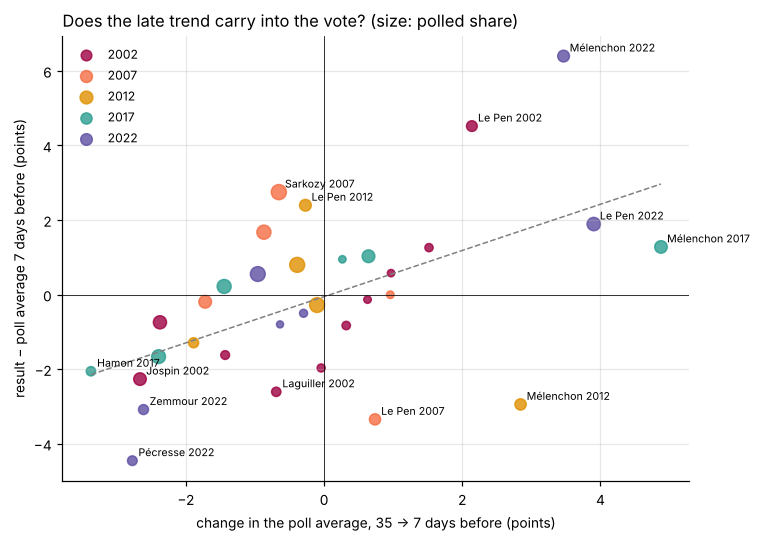

In [16]:
late = []
for (e, s), r in w.iterrows():
    m7, m35 = r.get(7), r.get(35)
    if pd.notna(m7) and pd.notna(m35) and m7 >= 3:
        res_ = results[(results["election"] == e) & (results["candidate"] == s)]["share"]
        if len(res_):
            late.append(dict(election=e, slot=s, before=m7 - m35, after=res_.iloc[0] - m7, level=m7))
late = pd.DataFrame(late)
lo, hi = boot(late)
print(f"Last mile against the 4 weeks before: slope {slope(late):.2f} (95% interval {lo:.2f} to {hi:.2f}), "
      f"{len(late)} candidates")
late.round(2).to_csv(TABLES / "momentum_into_the_vote.csv", index=False)

fig, ax = plt.subplots(figsize=(7, 5))
for e in ELECTIONS:
    d = late[late["election"] == e]
    ax.scatter(d["before"], d["after"], s=12 + d["level"] * 3, color=E_COLOURS[e], alpha=0.8, label=str(e))
    for r in d[(d["after"].abs() >= 2) | (d["before"].abs() >= 3)].itertuples():
        ax.annotate(f"{r.slot.split(' ', 1)[1]} {e}", (r.before, r.after), fontsize=7, xytext=(4, 3),
                    textcoords="offset points")
xs = np.linspace(late["before"].min(), late["before"].max(), 10)
ax.plot(xs, np.polyval(np.polyfit(late["before"], late["after"], 1), xs), color="grey", lw=1, ls="--")
ax.axhline(0, color="black", lw=0.5); ax.axvline(0, color="black", lw=0.5)
ax.set_xlabel("change in the poll average, 35 → 7 days before (points)")
ax.set_ylabel("result − poll average 7 days before (points)")
ax.set_title("Does the late trend carry into the vote? (size: polled share)", loc="left")
ax.legend(frameon=False, fontsize=8)
fig.tight_layout()
fig.savefig(FIGURES / "momentum_into_the_vote.png")

## 6 · Stylized facts

The numbers of Parts 1 and 2 in one table, one column per election, each row read from the committed table named in
`source`: the patterns the model should reproduce, 2002 and 2022 as the cases it replays, 2007, 2012 and 2017 as
out-of-sample cases.

In [17]:
T = lambda name, **kw: pd.read_csv(TABLES / name, **kw)
facts = []
def add(group, fact, values, source):
    facts.append({"group": group, "fact": fact, **{int(k): v for k, v in dict(values).items()}, "source": source})

sr = T("structure_results.csv", index_col="election")
for col, label in [("enp", "ENP"), ("hhi", "HHI"), ("top2_share", "top-two share (%)"),
                   ("cliff", "cliff: largest drop (points)"), ("cliff_location", "cliff location (candidates above)"),
                   ("cliff_ratio", "cliff ratio"), ("gap_23", "gap 2nd − 3rd (points)")]:
    add("result", label, sr[col], "structure_results.csv")

lv = T("structure_last_polls_vs_result.csv", header=[0, 1], index_col=0)
lv.index = lv.index.astype(int)
for col, label in [("enp", "ENP"), ("gap_23", "gap 2nd − 3rd (points)"), ("cliff", "cliff: largest drop (points)")]:
    add("last two weeks of polls", label, lv[(col, "last polls")], "structure_last_polls_vs_result.csv")

dc = T("concentration_decomposition.csv", index_col="election")
for col, label in [("campaign: voters (core)", "campaign ΔHHI: voters"), ("campaign: offer (composition)", "campaign ΔHHI: offer"),
                   ("last mile: total", "last-mile ΔHHI (all voters)")]:
    add("concentration", label, dc[col], "concentration_decomposition.csv")

rk = T("ranks_right_pair_by_phase.csv", index_col="election")
add("runoff pair", "share of polls with the real pair, last two weeks", rk["last two weeks"], "ranks_right_pair_by_phase.csv")
lk = T("ranks_lockin.csv", index_col="election")
add("runoff pair", "locked in the poll average from (days before)", lk["locked_from_days_before"], "ranks_lockin.csv")
cp = T("cliff_predictability.csv")
for h in ["4 weeks", "1 week"]:
    add("runoff pair", f"probability the polls gave the real pair, {h} before",
        cp[cp["horizon"] == h].set_index("election")["p_real_pair"], "cliff_predictability.csv")

er = T("error_by_candidate.csv")
add("poll error", "3rd in the last polls: result − polls", er[er["role"] == "3rd"].set_index("election")["error"], "error_by_candidate.csv")
add("poll error", "4th in the last polls: result − polls", er[er["role"] == "4th"].set_index("election")["error"], "error_by_candidate.csv")
add("poll error", "mean absolute error, candidates polled ≥ 5%",
    er[er["polled"] >= 5].groupby("election")["error"].apply(lambda x: x.abs().mean()), "error_by_candidate.csv")
ep = T("error_by_poll.csv")
add("poll error", "error of one poll on a typical candidate, last two weeks (RMSE, mean over polls)",
    ep.groupby("election")["rmse"].mean(), "error_by_poll.csv")

mo = T("momentum_campaign.csv", index_col="sample")
add("dynamics", "momentum: 3-week persistence (slope)", mo.drop(index="all")["slope"].rename(index=int), "momentum_campaign.csv")
vo = T("trajectories_volatility.csv", index_col="election")
add("dynamics", "volatility, last two weeks (points per week)", vo["last two weeks"], "trajectories_volatility.csv")

nz = T("noise_effective_sample_size.csv")
add("polls", "effective sample size, last two weeks", nz[nz["period"] == "last two weeks"].set_index("election")["n_eff"], "noise_effective_sample_size.csv")
hd = T("pollsters_herding.csv", index_col=["election", "phase"])
add("polls", "scatter / sampling noise, last two weeks (herding below 1)", hd.xs("last two weeks", level="phase")["ratio"], "pollsters_herding.csv")
cv = T("coverage_by_election.csv", index_col="election")
add("polls", "polls in the last two weeks", cv["last two weeks"], "coverage_by_election.csv")

facts = pd.DataFrame(facts)
facts.to_csv(TABLES / "stylized_facts.csv", index=False)
pd.set_option("display.max_colwidth", 60)
facts.set_index(["group", "fact"])[ELECTIONS].astype(float).round(3)

2002      2007      2012      2017     2022
group                   fact                                                                                                        
result                  ENP                                                             8.659     4.700     4.772     5.318    5.231
                        HHI                                                             0.116     0.213     0.210     0.188    0.191
                        top-two share (%)                                              36.740    57.050    55.810    45.310   51.000
                        cliff: largest drop (points)                                    9.340     8.130     9.280    13.220   14.880
                        cliff location (candidates above)                               3.000     3.000     2.000     4.000    3.000
                        cliff ratio                                                     0.928     0.782     0.795     0.918    0.923
                        gap 2nd − 3rd (points)                                          0.680     7.300     9.280     1.290    1.200
last two weeks of polls ENP                                                             8.732     5.099     4.834     5.340    5.867
                        gap 2nd − 3rd (points)                                          5.250     5.528    10.833     2.955    5.990
                        cliff: largest drop (points)                                    6.125     9.944    11.042    10.523    7.576
concentration           campaign ΔHHI: voters                                          -0.032    -0.041    -0.020    -0.009    0.006
                        campaign ΔHHI: offer                                            0.004    -0.002     0.042     0.006    0.020
                        last-mile ΔHHI (all voters)                                     0.001     0.016     0.003     0.001    0.020
runoff pair             share of polls with the real pair, last two weeks               0.000     1.000     1.000     0.950    1.000
                        locked in the poll average from (days before)                     NaN   204.000   208.000    86.000   96.000
                        probability the polls gave the real pair, 4 weeks before        0.024     0.783     0.973     0.800    0.838
                        probability the polls gave the real pair, 1 week before         0.040     0.940     0.999     0.721    0.978
poll error              3rd in the last polls: result − polls                           4.152     0.042     2.192     0.783    5.826
                        4th in the last polls: result − polls                          -1.905    -3.504    -3.067     0.694   -2.775
                        mean absolute error, candidates polled ≥ 5%                     1.611     2.038     1.413     0.965    2.498
                        error of one poll on a typical candidate, last two weeks ...    1.595     1.616     1.458     0.942    2.376
dynamics                momentum: 3-week persistence (slope)                            0.999     0.492     0.545     0.269    0.377
                        volatility, last two weeks (points per week)                    0.740     0.260     0.320     0.550    0.960
polls                   effective sample size, last two weeks                         935.300  1003.920  1073.480  1813.730  861.030
                        scatter / sampling noise, last two weeks (herding below 1)      1.070     1.000     0.930     0.730    2.090
                        polls in the last two weeks                                    12.000    18.000    12.000    22.000   29.000